# 04 · Comparativa y producción

**Objetivo de este cuaderno:** leer los artefactos de los cuadernos 02 y 03, comparar **exactitud, tamaño y latencia**, y sacar conclusiones que se puedan llevar a un servicio real. Aquí no se reentrena. Si faltan `resultados/mnist.json` o `resultados/sentimiento.json`, vuelve atrás y ejecuta 02 y 03.

La pregunta que organiza esta comparativa no es «¿quién tiene más exactitud?». Es: **¿qué calidad conserva el estudiante, a qué coste de inferencia, y qué habría que registrar y vigilar si lo pusiéramos en producción?**


In [1]:
from pathlib import Path
import os, sys, json, time, gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _raiz():
    aqui = Path.cwd().resolve()
    for cand in [aqui, *aqui.parents]:
        if (cand / "src" / "destilacion_utils.py").exists() and (cand / "notebooks").is_dir():
            return cand
    raise FileNotFoundError(
        "No encuentro la raiz del proyecto de destilacion "
        "(src/destilacion_utils.py + notebooks/)."
    )

RAIZ = _raiz()
sys.path.insert(0, str(RAIZ / "src"))

from destilacion_utils import (
    preparar_rutas,
    fijar_semilla,
    dispositivo,
    configurar_proxy_y_hf,
    comprobar_entorno,
    probar_conexion_hf,
    texto_ayuda_proxy,
    softmax_temperatura,
    divergencia_kl,
    perdida_destilacion,
    construir_mlp,
    construir_estudiante_sentimiento,
    contar_parametros,
    tamano_archivo_mb,
    guardar_json,
    cargar_json,
    guardar_checkpoint,
    cargar_checkpoint,
    evaluar_loader,
    medir_latencia_ms,
    entrenar_epoca,
)

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    import matplotlib
    matplotlib.use("Agg")

plt.rcParams.update({
    "figure.figsize": (8, 4.2),
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titlesize": 12,
    "figure.dpi": 110,
})

RUTAS = preparar_rutas(RAIZ)
SEMILLA = fijar_semilla()
CFG_RED = configurar_proxy_y_hf(RAIZ, verbose=True)
DEVICE = dispositivo()
print(f"Raiz:        {RAIZ}")
print(f"Dispositivo: {DEVICE}")
print(f"Semilla:     {SEMILLA}")


Configuración de red y Hugging Face
  HTTP_PROXY definido:  False
  HTTPS_PROXY definido: False
  NO_PROXY definido:    False
  Certificado SSL (SSL_CERT_FILE / REQUESTS_CA_BUNDLE): False
  Token de Hugging Face presente: False (no se muestra el valor)
  HF_HOME: /workspace/destilacion/cache-hf
  Modo offline HF: False
  No hizo falta ajustar variables: ya estaban definidas.
Raiz:        /workspace/destilacion
Dispositivo: cpu
Semilla:     42


## 1. Cargar resultados de 02 y 03


In [2]:
ruta_mnist = RUTAS["resultados"] / "mnist.json"
ruta_sent = RUTAS["resultados"] / "sentimiento.json"
faltan = [str(p) for p in (ruta_mnist, ruta_sent) if not p.exists()]
assert not faltan, (
    "Faltan resultados de cuadernos anteriores:\n- "
    + "\n- ".join(faltan)
    + "\nEjecuta 02-destilacion-mnist-mlp.ipynb y 03-destilacion-bert-sentimiento.ipynb en ese orden."
)

mnist = cargar_json(ruta_mnist)
sent = cargar_json(ruta_sent)

def filas_de(nombre_problema, bloque):
    out = []
    for rol, d in bloque["modelos"].items():
        out.append(
            {
                "problema": nombre_problema,
                "modelo": rol,
                "parametros": d.get("parametros"),
                "tamano_mb": d.get("tamano_mb"),
                "exactitud_test": d.get("exactitud"),
                "ms_por_ejemplo": d.get("latencia_ms_por_ejemplo_media"),
                "ms_lote_p95": d.get("latencia_ms_lote_p95"),
                "tamano_lote_latencia": d.get("latencia_tamano_lote"),
                "dispositivo": bloque.get("dispositivo"),
                "temperature": bloque.get("temperature"),
                "alpha": bloque.get("alpha"),
            }
        )
    return out

comparativa = pd.DataFrame(filas_de("MNIST / MLP", mnist) + filas_de("SST-2 / DistilBERT→GRU", sent))
comparativa


,problema,modelo,parametros,tamano_mb,exactitud_test,ms_por_ejemplo,ms_lote_p95,tamano_lote_latencia,dispositivo,temperature,alpha
0,MNIST / MLP,profesor,235146,0.900430,0.969200,0.001200,0.080909,64,cpu,4.0,0.5
1,MNIST / MLP,estudiante_duro,25450,0.100015,0.841200,0.000362,0.024423,64,cpu,4.0,0.5
2,MNIST / MLP,estudiante_destilado,25450,0.100123,0.863800,0.000355,0.023887,64,cpu,4.0,0.5
3,SST-2 / DistilBERT→GRU,profesor,66955010,NaN,0.910550,8.694339,233.251669,16,cpu,3.0,0.7
4,SST-2 / DistilBERT→GRU,estudiante_duro,2003586,7.648153,0.650229,0.079180,2.766962,32,cpu,3.0,0.7
5,SST-2 / DistilBERT→GRU,estudiante_destilado,2003586,7.648295,0.674312,0.080409,2.799663,32,cpu,3.0,0.7


## 2. Lectura de las cifras

Tres ángulos, en los dos problemas:

1. **Calidad:** ¿cuánto se deja el estudiante destilado respecto al profesor? ¿Mejora al estudiante duro?
2. **Tamaño:** parámetros y, cuando hay fichero, megas en disco. En sentimiento el profesor es un identificador de Hugging Face, no un `.pt` nuestro; el dato útil es el recuento de parámetros.
3. **Latencia:** milisegundos por ejemplo en el dispositivo en el que se midió (queda anotado). Es una medida de *esta máquina*, no un SLO de producción. Sirve para comparar modelos entre sí en las mismas condiciones.


,problema,acc_profesor,acc_estudiante_duro,acc_estudiante_destilado,hueco_destilado_vs_profesor,mejora_vs_duro,params_profesor,params_estudiante,ratio_params_est/prof,aceleracion_latencia_prof/est
0,MNIST / MLP,0.9692,0.8412,0.8638,-0.1054,0.0226,235146,25450,0.1082,3.3781
1,SST-2 / DistilBERT→GRU,0.9106,0.6502,0.6743,-0.2362,0.0241,66955010,2003586,0.0299,108.1268


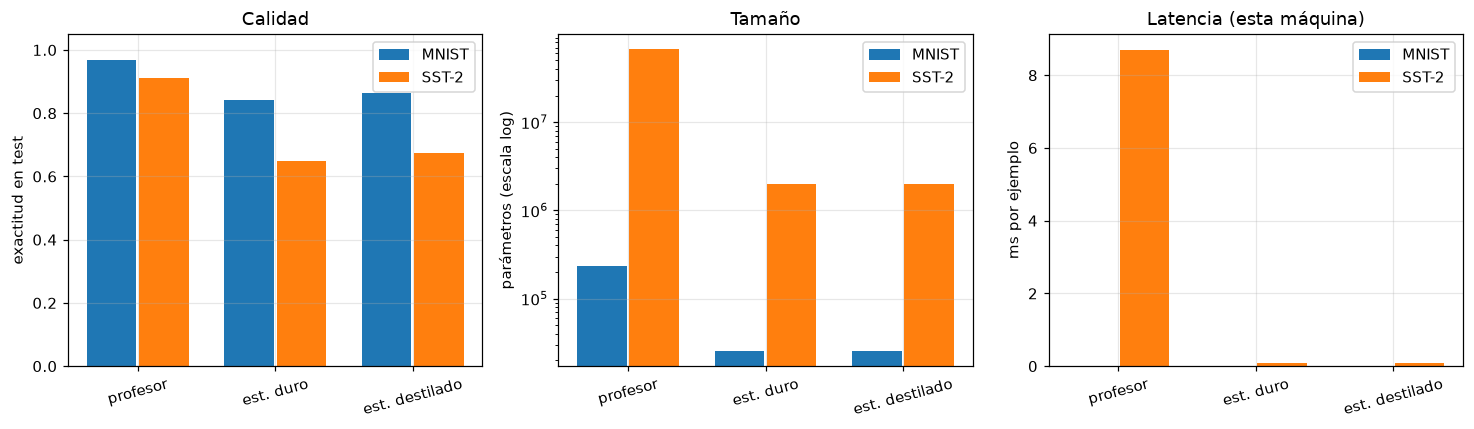

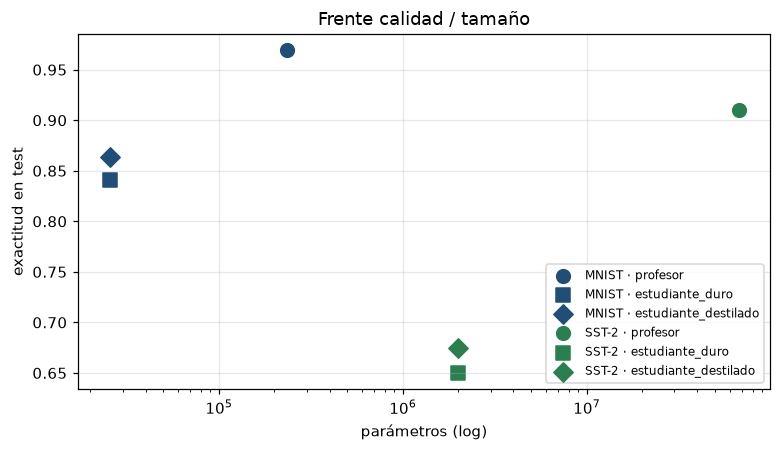

In [3]:
def hueco(bloque, rol_a, rol_b, campo="exactitud"):
    return bloque["modelos"][rol_a][campo] - bloque["modelos"][rol_b][campo]


resumen = []
for nombre, bloque in [("MNIST / MLP", mnist), ("SST-2 / DistilBERT→GRU", sent)]:
    m = bloque["modelos"]
    acc_p = m["profesor"]["exactitud"]
    acc_d = m["estudiante_duro"]["exactitud"]
    acc_k = m["estudiante_destilado"]["exactitud"]
    lat_p = m["profesor"]["latencia_ms_por_ejemplo_media"]
    lat_k = m["estudiante_destilado"]["latencia_ms_por_ejemplo_media"]
    par_p = m["profesor"]["parametros"]
    par_k = m["estudiante_destilado"]["parametros"]
    resumen.append(
        {
            "problema": nombre,
            "acc_profesor": acc_p,
            "acc_estudiante_duro": acc_d,
            "acc_estudiante_destilado": acc_k,
            "hueco_destilado_vs_profesor": acc_k - acc_p,
            "mejora_vs_duro": acc_k - acc_d,
            "params_profesor": par_p,
            "params_estudiante": par_k,
            "ratio_params_est/prof": par_k / par_p,
            "aceleracion_latencia_prof/est": lat_p / lat_k if lat_k else None,
        }
    )

tabla_resumen = pd.DataFrame(resumen)
display(tabla_resumen.round(4))

# Figuras.
fig, ejes = plt.subplots(1, 3, figsize=(13.5, 4.0))

# Exactitud
for i, (nombre, bloque, color_base) in enumerate(
    [("MNIST", mnist, 0), ("SST-2", sent, 1)]
):
    xs = np.arange(3)
    vals = [
        bloque["modelos"]["profesor"]["exactitud"],
        bloque["modelos"]["estudiante_duro"]["exactitud"],
        bloque["modelos"]["estudiante_destilado"]["exactitud"],
    ]
    ejes[0].bar(xs + i * 0.38 - 0.19, vals, width=0.36, label=nombre)
ejes[0].set_xticks([0, 1, 2])
ejes[0].set_xticklabels(["profesor", "est. duro", "est. destilado"], rotation=15)
ejes[0].set_ylim(0, 1.05)
ejes[0].set_ylabel("exactitud en test")
ejes[0].set_title("Calidad")
ejes[0].legend()

# Parámetros (log)
for i, (nombre, bloque) in enumerate([("MNIST", mnist), ("SST-2", sent)]):
    xs = np.arange(3)
    vals = [
        bloque["modelos"]["profesor"]["parametros"],
        bloque["modelos"]["estudiante_duro"]["parametros"],
        bloque["modelos"]["estudiante_destilado"]["parametros"],
    ]
    ejes[1].bar(xs + i * 0.38 - 0.19, vals, width=0.36, label=nombre)
ejes[1].set_xticks([0, 1, 2])
ejes[1].set_xticklabels(["profesor", "est. duro", "est. destilado"], rotation=15)
ejes[1].set_yscale("log")
ejes[1].set_ylabel("parámetros (escala log)")
ejes[1].set_title("Tamaño")
ejes[1].legend()

# Latencia
for i, (nombre, bloque) in enumerate([("MNIST", mnist), ("SST-2", sent)]):
    xs = np.arange(3)
    vals = [
        bloque["modelos"]["profesor"]["latencia_ms_por_ejemplo_media"],
        bloque["modelos"]["estudiante_duro"]["latencia_ms_por_ejemplo_media"],
        bloque["modelos"]["estudiante_destilado"]["latencia_ms_por_ejemplo_media"],
    ]
    ejes[2].bar(xs + i * 0.38 - 0.19, vals, width=0.36, label=nombre)
ejes[2].set_xticks([0, 1, 2])
ejes[2].set_xticklabels(["profesor", "est. duro", "est. destilado"], rotation=15)
ejes[2].set_ylabel("ms por ejemplo")
ejes[2].set_title("Latencia (esta máquina)")
ejes[2].legend()

fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_comparativa_global.png", bbox_inches="tight")
plt.show()

# Frente Pareto: tamaño vs exactitud.
fig, ax = plt.subplots(figsize=(7.2, 4.2))
marcas = {"profesor": "o", "estudiante_duro": "s", "estudiante_destilado": "D"}
colores = {"MNIST / MLP": "#1f4e79", "SST-2 / DistilBERT→GRU": "#2a7f4f"}
for _, fila in comparativa.iterrows():
    ax.scatter(
        fila["parametros"],
        fila["exactitud_test"],
        marker=marcas[fila["modelo"]],
        color=colores[fila["problema"]],
        s=80,
        label=f"{fila['problema'].split(' / ')[0]} · {fila['modelo']}",
    )
ax.set_xscale("log")
ax.set_xlabel("parámetros (log)")
ax.set_ylabel("exactitud en test")
ax.set_title("Frente calidad / tamaño")
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
fig.savefig(RUTAS["resultados"] / "fig_comparativa_pareto.png", bbox_inches="tight")
plt.show()


### Cómo leerlo

- En MNIST el contraste de latencia es pequeño: ambos modelos son MLP diminutos para una CPU moderna. El valor del experimento está en la **calidad con pocos datos**, no en el ahorro de milisegundos.
- En sentimiento el contraste de tamaño y de latencia es el que importa en un servicio: el profesor es un transformer; el estudiante, un GRU con un embedding compacto. El hueco de exactitud es el precio. Si ese precio cabe en el acuerdo de calidad del servicio, el estudiante es el que debería ir en el camino de la petición.
- «Mejora vs duro» es la ganancia *atribuible a destilar*, no a la arquitectura. Los dos estudiantes son el mismo modelo, con los mismos pesos iniciales.


## 3. Remedir latencia (opcional)

Si los pesos siguen en `modelos/`, se vuelve a medir en esta máquina. No es obligatorio: las cifras de 02 y 03 ya están en el JSON. Sirve para comprobar que el artefacto se carga y que la medida no dependía de un estado transitorio (otros procesos, primera ejecución, etc.).


In [4]:
import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

remeidiciones = []

# MNIST: reconstruir un lote y los tres MLP.
ruta_p = RAIZ / mnist["modelos"]["profesor"]["ruta"]
ruta_d = RAIZ / mnist["modelos"]["estudiante_duro"]["ruta"]
ruta_k = RAIZ / mnist["modelos"]["estudiante_destilado"]["ruta"]
if all(p.exists() for p in (ruta_p, ruta_d, ruta_k)):
    tfm = transforms.Compose(
        [
            transforms.ToTensor(),
            transforms.Normalize((0.1307,), (0.3081,)),
            transforms.Lambda(lambda t: t.reshape(-1)),
        ]
    )
    test_full = datasets.MNIST(RUTAS["datos"] / "mnist", train=False, download=False, transform=tfm)
    lote = next(iter(DataLoader(test_full, batch_size=64, shuffle=False)))[0]
    drop_p = mnist.get("dropout_profesor", 0.2)
    drop_e = mnist.get("dropout_estudiante", 0.0)
    for rol, ruta, anchos, drop in [
        ("profesor", ruta_p, mnist["modelos"]["profesor"]["anchos"], drop_p),
        ("estudiante_duro", ruta_d, mnist["modelos"]["estudiante_duro"]["anchos"], drop_e),
        ("estudiante_destilado", ruta_k, mnist["modelos"]["estudiante_destilado"]["anchos"], drop_e),
    ]:
        modelo = construir_mlp(anchos, dropout=drop).to(DEVICE)
        cargar_checkpoint(modelo, ruta, map_location="cpu")
        modelo.to(DEVICE).eval()
        lat = medir_latencia_ms(modelo, lote, device=DEVICE)
        remeidiciones.append({"problema": "mnist", "modelo": rol, **lat})
        del modelo
else:
    print("No están los tres pesos de MNIST; se mantiene la latencia del JSON.")

display(pd.DataFrame(remeidiciones) if remeidiciones else "Sin remedición de MNIST.")
guardar_json(
    {"comparativa": comparativa.to_dict(orient="records"), "resumen": resumen, "remeidiciones": remeidiciones},
    RUTAS["resultados"] / "comparativa.json",
)
print("Escrito resultados/comparativa.json")


,problema,modelo,ms_lote_media,ms_lote_p50,ms_lote_p95,ms_por_ejemplo_media,n_reps,tamano_lote
0,mnist,profesor,0.131687,0.130968,0.144679,0.002058,40,64
1,mnist,estudiante_duro,0.030413,0.029976,0.033807,0.000475,40,64
2,mnist,estudiante_destilado,0.030865,0.030067,0.035010,0.000482,40,64


Escrito resultados/comparativa.json


## 4. Conclusiones de MLOps

Estas son las que conviene llevarse, más allá de MNIST y SST-2.

### Qué registrar junto al estudiante

No basta con un `estudiante.pt` y una exactitud. Un experimento de destilación, para poder repetirlo y auditarlo, debería dejar constancia de:

- Identidad del **profesor**: nombre o ruta, revisión (`commit` del Hub o hash del fichero), número de parámetros.
- Identidad del **estudiante**: arquitectura, hiperparámetros, hash de pesos.
- **Datos:** origen, recuento, partición, semilla, identificador o hash del subconjunto.
- **Hiperparámetros de destilación:** \(T\), \(\alpha\), épocas, lote, tasa de aprendizaje.
- **Métricas:** exactitud (o la métrica de negocio) del profesor, del estudiante duro y del destilado, en validación y en test; acuerdo profesor-estudiante; tamaño; latencia p50 y p95 en un hardware descrito.
- El **tokenizador** o el preprocesamiento, versionado con el estudiante. No es un detalle: es parte del modelo.

En MLflow (o el registro que use el curso) eso son parámetros, métricas y artefactos de un mismo *run*. El profesor y el estudiante se promocionan **como pareja**.

### Criterio de promoción, no solo «el más exacto»

Un estudiante entra en el camino de la petición si cumple *a la vez*:

- un suelo de calidad (por ejemplo, no alejarse más de X puntos del profesor en test, o de un mínimo de negocio);
- un techo de coste (p95 de latencia, memoria, tamaño de imagen).

Si solo se mira la exactitud, el profesor siempre gana y no se despliega nada más barato. Si solo se mira la latencia, se puede promocionar un modelo que no cumple el acuerdo de calidad.

### El profesor no vive en la petición (o no debería)

El patrón de este material es deliberado: el profesor etiqueta o genera blandas **fuera** del request (aquí, precomputadas; en un sistema, en un job). El estudiante responde a la petición. El profesor se puede usar, de vez en cuando, como **sombra** sobre una muestra del tráfico para medir el acuerdo con el estudiante. Esa divergencia es una señal de deriva: cambió el lenguaje de entrada, cambió el profesor, o el estudiante se quedó viejo.

### Si actualizas al profesor, redestila

Un profesor nuevo (reentrenado, otra revisión del Hub) no se «hereda» solo. El estudiante hay que volver a destilarlo, evaluarlo y promoverlo. El versionado tiene que dejar claro *con qué profesor* se destiló cada estudiante.

### Riesgos que no desaparecen al destilar

- El estudiante **hereda sesgos** y errores del profesor. Si el profesor está mal calibrado, las blandas copian esa calibración.
- Un profesor mediocre destilado con \(\alpha\) alto puede ser peor que entrenar al estudiante solo con etiquetas duras de calidad (el cuaderno 05 incluye un ejercicio sobre un «profesor» aleatorio).
- La latencia medida en un portátil no es la del contenedor en producción: hay que volver a medirla en el entorno real, con el lote real, en caliente.

### Cuándo merece la pena destilar

Tiene sentido cuando hay un profesor claramente mejor (más datos, más capacidad, ya validado) y una restricción real de coste o de latencia en el camino de la petición. Tiene menos sentido cuando el estudiante, con las etiquetas duras y los datos disponibles, ya iguala al profesor, o cuando no hay forma de servir el preprocesamiento del profesor junto al estudiante.


## Cierre

`resultados/comparativa.json` resume las cifras de 02 y 03. El cuaderno 05 parte de esta interpretación y pide decidir hiperparámetros, un criterio de promoción y lo que registrarías en un *run*.

Siguiente: `05-ejercicios.ipynb`.
